# Sri Lanka Leptospirosis ML: ensemble modelling and explanation

This notebook is the main modelling walkthrough: precise feature decisions → bagging, boosting and stacking → development-only model selection → held-out evidence → explanation of the selected model → serving and MLOps.

The earlier `analysis.ipynb` remains a historical course analysis. This notebook reads the new reproducible benchmark from `../reports/` and the deployed estimator from `../artifacts/`. Saved-results analysis requires no raw patient CSV. Source labels, units and the 99 missing convention remain provisional; this is an academic demonstration, not clinical guidance.

## 1. Load the versioned experiment
Use the Python 3.12 environment from `requirements-dev.txt`. Retraining is optional and disabled by default.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / 'app.py').exists() else Path.cwd().parent
assert (ROOT / 'app.py').exists(), 'Run from the project root or leptospirosis_project folder.'
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
REPORTS = ROOT / 'reports'
read_json = lambda name: json.loads((REPORTS / name).read_text(encoding='utf-8'))
selection = read_json('selection.json')
test = read_json('test_results.json')
cv = pd.read_csv(REPORTS / 'cv_candidates.csv')
folds = pd.read_csv(REPORTS / 'cv_folds.csv')
leaderboard = pd.read_csv(REPORTS / 'cv_leaderboard.csv')
from src.runtime import load_release
model, reference, manifest = load_release(ROOT)
print('Verified model version:', manifest['model_version'])
print(test['notice'])

Verified model version: 503bc9aeb6f8
Research demonstration only. Final code 1 and code 2 have unverified clinical meanings. The 99 missing-value convention and measurement units are provisional. Scores are uncalibrated model outputs, not clinical risks.


In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    from train import run
    run()  # Requires the local source CSV; rerun the load cell after completion.


## 2. Feature engineering with precise reasoning
The decisions below state the exact operation, reason, assumptions, leakage boundary and validation evidence. Derived fields are computed before imputation. Learned preprocessing is fitted only on fitting folds.

In [3]:
display(Markdown((REPORTS / 'FEATURE_ENGINEERING.md').read_text(encoding='utf-8')))
display(pd.read_csv(REPORTS / 'feature_audit.csv'))

# Feature engineering: decisions and evidence

The prediction point is admission. Source labels and units remain provisional. The new benchmark uses 54 original inputs (4 numeric and 50 categorical codes). The engineered variant adds four derived inputs. No step uses the target to create a feature.

| Decision | Exact implementation | Reason | Limitation / evidence |
|---|---|---|---|
| Admission-only allowlist | Age, Sex, four admission-vital fields including age, 29 admission symptom fields, 20 exposure fields; see `src/data.py` for exact names | Features should be available at the stated prediction time | Exposure history is assumed available at admission; timing still needs source verification |
| Exclude IDs and collection context | Exclude Serial, Hospital, Sample, Year, Month, ICU/OPD and all other unlisted fields | IDs encourage memorization; site/sample/time can proxy recruitment or outcomes; ICU may be downstream | Site and temporal external validation remain necessary; excluding site alone does not remove site effects |
| Exclude diagnostic/follow-up fields | Final, MAT, PCR, serial-day measurements and uncertain-time laboratory fields are never predictors | Tests defining or revealing the outcome and measurements obtained later cause leakage | A verified availability/codebook audit could enable a different admission-only contract |
| Eligible cohort | Only Final in {1,2} and at least one recorded admission symptom | Match the prior project cohort; avoid predicting from wholly absent admission symptom records | Excludes patients systematically; results apply only to this selected cohort |
| Missing source values | Parse numerics; convert 99, blank, unparsable entries to missing | 99 dominates missing blocks; this preserves the earlier project's provisional convention | Not codebook-confirmed. A real value of 99 (e.g. pulse or age) would be lost; verify before substantive research interpretation |
| Numeric bounds | Age [0,110], PRad [20,250], SBPadd [40,300], DBPadd [20,200]; outside values become missing | Deterministic protection against invalid source codes and gross data-entry errors | Broad project validation bounds, not clinical reference ranges. No clipping or learned outlier removal |
| Categorical representation | Only 1/2 retained; missing becomes an explicit Missing category; one-hot encoding handles unseen codes | Avoid assuming code 2 is twice code 1 or that code 1 means symptom present | Keep neutral codes until codebook verification. Encoding is fitted inside each fold |
| Numeric imputation | Fold-training median with missing indicators; retain empty features | Robust to extreme numeric values and preserves the fact that an input was unrecorded | Missing indicators may learn collection practices; no population-wide median is fitted |
| Numeric scaling | Standardize after imputation using fold-training means/SDs | Useful for logistic models; gives every family the same preprocessing contract | Tree models do not require scaling; it does not create information |
| Pulse pressure candidate | SBPadd − DBPadd, only if both observed and SBP ≥ DBP | Exposes a deterministic interaction that shallow/additive learners might otherwise need to discover | Assumes both pressures share source units; correlated with original pressures and often missing |
| Mean arterial pressure candidate | DBPadd + (SBPadd − DBPadd)/3, same validity mask | Makes a weighted summary of two existing numeric inputs available to low-depth models | An approximation, not a new measured value; units/semantics unverified; kept only as a candidate representation |
| Symptom recording fraction candidate | Number of nonmissing symptom codes divided by 29, before imputation | Distinguish sparse documentation from fully recorded symptom history | Counts documentation, not symptoms present; can encode site practices |
| Exposure recording fraction candidate | Number of nonmissing exposure codes divided by 20, before imputation | Distinguish unrecorded history from recorded source codes | Counts documentation, not exposures present; shift-sensitive |
| Reject positive-code counts | No symptom burden / exposure burden based on code 1 | The presence/absence mapping is unverified | A codebook is required before such aggregations are meaningful |
| Reject arbitrary feature removal | No whole-dataset correlation/importance screening; no post-test feature dropping | Preserve leakage boundaries and avoid test-driven choices | 54 original inputs with correlated fields can dilute individual importance |
| Reject synthetic oversampling here | Original class proportions; equal class weights across all new candidates | Moderate code imbalance; consistent objective across ensemble families; avoid creating mixtures of sparse categorical records | ROC AUC alone does not solve imbalance; report AP, class prevalence, recall, precision, F1 and calibration metrics |

## How feature engineering is retained or rejected

Both `base` and `engineered` representations are declared before the new run. They use exactly the same development folds and every estimator refits all learned preprocessing inside its fitting fold. Stacking owns complete base pipelines inside its three inner folds, preventing preprocessing leakage into meta-learner training.

`feature_ablation.csv` compares each model's best development configuration under both representations. Its `engineered_minus_base` column reports the change in mean validation ROC AUC. Hyperparameters can differ between these best configurations, so it is a representation-plus-tuning comparison rather than a controlled single-parameter causal effect. `cv_candidates.csv` also permits matched-candidate comparisons.

The overall selection chooses the complete model/feature-set/candidate combination with the highest development mean ROC AUC. The exact-AUC tie-breaker is mean average precision, followed by deterministic name/feature/candidate order. Therefore engineered inputs are not retained merely because they sound plausible. The selected representation is recorded in `selection.json`; `MODEL_CARD.md` states the measured outcome.

No further predictor is added or removed after seeing test performance or explainability results. The historical holdout has already been examined in the previous analysis; this is internal research validation. Multiple model/feature comparisons can make the winning CV estimate optimistic; fresh external or temporal evaluation is future work.


,feature,development_missing_fraction,type
0,Age,0.008299,numeric
1,PRad,0.390041,numeric
2,SBPadd,0.387967,numeric
3,DBPadd,0.387967,numeric
4,Sex,0.003112,categorical source code
5,Feverad,0.010373,categorical source code
6,Headachead,0.010373,categorical source code
7,Chillsad,0.012448,categorical source code
8,Rigorsad,0.011411,categorical source code
9,Musclepainad,0.010373,categorical source code


### Inspect the actual transform and synthetic example
The transformer does not learn population statistics. Inspecting its source makes the notebook consistent with the training and serving implementation.

In [4]:
import inspect
from src.data import AdmissionFeatures, validate_record
from src.models import pipeline
print(inspect.getsource(AdmissionFeatures))
print(inspect.getsource(pipeline))
synthetic = validate_record({'Age':35, 'Feverad':1, 'SBPadd':120, 'DBPadd':80})
display(AdmissionFeatures(True).fit_transform(synthetic)[['Age','pulse_pressure','mean_arterial_pressure','symptoms_recorded_fraction','exposures_recorded_fraction']])

class AdmissionFeatures(TransformerMixin, BaseEstimator):
    """No fitted statistics; derived values calculated before fold-local imputation."""
    def __init__(self, engineered=False):
        self.engineered = engineered

    def fit(self, X, y=None):
        self.n_features_in_ = len(FEATURES)
        self.feature_names_in_ = np.array(FEATURES, dtype=object)
        return self

    def transform(self, X):
        out = X[FEATURES].copy()
        if self.engineered:
            valid = out.SBPadd.notna() & out.DBPadd.notna() & (out.SBPadd >= out.DBPadd)
            out['pulse_pressure'] = (out.SBPadd - out.DBPadd).where(valid)
            out['mean_arterial_pressure'] = (out.DBPadd + out['pulse_pressure'] / 3).where(valid)
            out['symptoms_recorded_fraction'] = out[SYMPTOMS].notna().mean(axis=1)
            out['exposures_recorded_fraction'] = out[EXPOSURES].notna().mean(axis=1)
        return out

    def get_feature_names_out(self, input_features=None):
        return n

,Age,pulse_pressure,mean_arterial_pressure,symptoms_recorded_fraction,exposures_recorded_fraction
0,35.0,40.0,93.333333,0.034483,0.0


### Development-only ablation
For each method, compare its best base configuration with its best engineered configuration. The full candidate table allows matched-hyperparameter comparisons. A positive difference supports that representation within this search; it is not proof of significance or a causal feature effect.

In [5]:
display(pd.read_csv(REPORTS / 'feature_ablation.csv'))

,model,base,engineered,engineered_minus_base
0,AdaBoost,0.586332,0.589123,0.002791
1,Bagged trees,0.599519,0.598177,-0.001342
2,CatBoost,0.596469,0.596636,0.000167
3,Extra trees,0.605375,0.599967,-0.005408
4,Gradient boosting,0.587771,0.579796,-0.007975
5,Histogram boosting,0.585148,0.579119,-0.006029
6,LightGBM,0.587581,0.579309,-0.008272
7,Logistic regression,0.599590,0.599135,-0.000455
8,Prior baseline,0.500000,0.500000,0.000000
9,Random forest,0.599768,0.602817,0.003049


## 3. Shared evaluation and declared recipes
The 80/20 stratified seed-42 split yields 964 development and 242 internal holdout records. Every recipe uses the same five development folds. The 36 recipes cover 13 methods with equal class weights. This historical holdout was already used in the earlier project, so it is not fresh external validation.

Within each outer fold, the model owns the feature transformer, imputer, encoder and scaler. Stacking owns complete raw-input pipelines inside its three inner folds; the meta-learner never receives in-sample base predictions. No preprocessing is fitted before those inner folds.

In [6]:
from src.models import candidates
recipes = candidates()
display(pd.DataFrame([{k:v for k,v in spec.items() if k != 'estimator'} for spec in recipes]))
print('Candidates:', len(recipes), '| outer fold rows:', len(folds))

Candidates: 36 | outer fold rows: 180


,model,family,feature_set,candidate
0,Prior baseline,Baseline,base,0
1,Prior baseline,Baseline,engineered,0
2,Logistic regression,Baseline,base,0
3,Logistic regression,Baseline,base,1
4,Logistic regression,Baseline,engineered,0
5,Logistic regression,Baseline,engineered,1
6,Bagged trees,Bagging,base,0
7,Bagged trees,Bagging,engineered,0
8,Random forest,Bagging,base,0
9,Random forest,Bagging,base,1


## 4. Bagging and randomized averaging
**Bagged trees** average bootstrap-fitted trees. **Random forest** adds random feature subsets at splits. **Extra Trees** randomizes split thresholds. Extra Trees uses `bootstrap=False` here, so it is a randomized averaging ensemble rather than literal bootstrap bagging. We compare them together as variance-reducing tree ensembles. Leaf-size constraints control overfitting. Each row below is that method's best development recipe; variability is fold SD, not a confidence interval.

In [7]:
display(leaderboard.loc[leaderboard.family == 'Bagging', ['model','feature_set','mean_roc_auc','std_roc_auc','mean_average_precision','mean_f1','mean_recall','mean_brier','mean_train_roc_auc','mean_fit_predict_seconds']])

,model,feature_set,mean_roc_auc,std_roc_auc,mean_average_precision,mean_f1,mean_recall,mean_brier,mean_train_roc_auc,mean_fit_predict_seconds
0,Extra trees,base,0.605375,0.049951,0.491954,0.289490,0.200000,0.230499,0.815443,0.287662
1,Random forest,engineered,0.602817,0.047675,0.484658,0.296500,0.208000,0.231210,0.886699,0.342530
4,Bagged trees,base,0.599519,0.042106,0.482555,0.300618,0.218667,0.232602,0.789167,0.466153


## 5. Boosting
Compare **AdaBoost**, **gradient boosting**, **histogram boosting**, **XGBoost**, **LightGBM** and **CatBoost**. Sequential learners improve a fitting objective; learning rate, shallow trees and regularization constrain capacity. All receive the same prepared features. CatBoost therefore uses one-hot inputs here; its native categorical mode is not evaluated. The compact grids are explicit and do not establish each library's best possible configuration.

In [8]:
display(leaderboard.loc[leaderboard.family == 'Boosting', ['model','feature_set','mean_roc_auc','std_roc_auc','mean_average_precision','mean_f1','mean_recall','mean_brier','mean_train_roc_auc','mean_fit_predict_seconds']])

,model,feature_set,mean_roc_auc,std_roc_auc,mean_average_precision,mean_f1,mean_recall,mean_brier,mean_train_roc_auc,mean_fit_predict_seconds
5,XGBoost,base,0.597895,0.043826,0.478317,0.315055,0.229333,0.232801,0.738667,0.145419
6,CatBoost,engineered,0.596636,0.050223,0.480327,0.265696,0.184000,0.233171,0.779561,0.319620
8,AdaBoost,engineered,0.589123,0.042212,0.459624,0.014286,0.008000,0.252144,0.635840,0.373315
9,Gradient boosting,base,0.587771,0.054947,0.476809,0.284737,0.197333,0.234940,0.763563,0.277725
10,LightGBM,base,0.587581,0.048873,0.484664,0.343325,0.266667,0.236619,0.812244,0.118224
11,Histogram boosting,base,0.585148,0.044186,0.475935,0.330004,0.253333,0.236018,0.802753,0.261632


## 6. Stacking
The base learners are logistic regression, random forest and gradient boosting. Compare a **regularized logistic** combiner with a **shallow nonlinear boosting** combiner. Three inner stratified folds generate meta-training predictions inside each of the five outer development folds. The held-out fold never selects or trains the combiner. Additional complexity must earn an improved development score.

In [9]:
display(leaderboard.loc[leaderboard.family == 'Stacking', ['model','feature_set','mean_roc_auc','std_roc_auc','mean_average_precision','mean_f1','mean_recall','mean_brier','mean_train_roc_auc','mean_fit_predict_seconds']])
print(next(s['estimator'] for s in recipes if s['model'] == 'Stacking logistic'))

StackingClassifier(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimators=[('lr',
                                Pipeline(steps=[('features',
                                                 AdmissionFeatures()),
                                                ('prepare',
                                                 ColumnTransformer(transformers=[('numeric',
                                                                                  Pipeline(steps=[('impute',
                                                                                                   SimpleImputer(add_indicator=True,
                                                                                                                 keep_empty_features=True,
                                                                                                                 strategy='median')),
                                                                                

,model,feature_set,mean_roc_auc,std_roc_auc,mean_average_precision,mean_f1,mean_recall,mean_brier,mean_train_roc_auc,mean_fit_predict_seconds
2,Stacking logistic,engineered,0.601535,0.057297,0.486726,0.000000,0.000000,0.233553,0.743252,1.629839
7,Stacking nonlinear,engineered,0.593814,0.057734,0.456713,0.120566,0.077333,0.232681,0.727704,1.670606


## 7. Select the complete recipe using explicit metrics
**Primary:** maximize mean development ROC AUC. **Exact ties:** maximize mean development average precision, then deterministic name/feature/candidate order. ROC AUC measures ranking across thresholds; AP provides prevalence-sensitive precision/recall context. Threshold-dependent F1, recall, precision and balanced accuracy describe behaviour at 0.50. Brier score and log loss describe probability error; lower is better. Training AUC and timing expose overfitting/computational cost but do not choose the winner.

The saved selection precedes holdout prediction. We do not pick the model by accuracy, by its test AUC, or by changing metrics after seeing results. Fold SD does not establish significance; selecting from many recipes can make the winning CV estimate optimistic.

Chosen: Extra trees / base


,model,family,feature_set,candidate,mean_roc_auc,std_roc_auc,mean_average_precision
0,Extra trees,Bagging,base,0,0.605375,0.049951,0.491954
1,Random forest,Bagging,engineered,0,0.602817,0.047675,0.484658
2,Stacking logistic,Stacking,engineered,0,0.601535,0.057297,0.486726
3,Stacking logistic,Stacking,base,0,0.600158,0.053763,0.486382
4,Extra trees,Bagging,engineered,0,0.599967,0.054664,0.484412
5,Random forest,Bagging,base,0,0.599768,0.050129,0.488284
6,Logistic regression,Baseline,base,0,0.599590,0.052038,0.487584
7,Bagged trees,Bagging,base,0,0.599519,0.042106,0.482555
8,Logistic regression,Baseline,engineered,0,0.599135,0.052101,0.486786
9,Random forest,Bagging,engineered,1,0.599103,0.045601,0.484377


{'selected_model': 'Extra trees',
 'family': 'Bagging',
 'feature_set': 'base',
 'candidate': 0,
 'spec_id': 12,
 'selection_metric': 'mean development 5-fold ROC AUC (higher is better)',
 'tie_breaker': 'mean development average precision for exact AUC ties; then deterministic name/feature/candidate order',
 'cv_roc_auc': 0.6053753440533101,
 'cv_auc_fold_std': 0.049950701304520874,
 'cv_average_precision': 0.4919544969992781,
 'threshold': 0.5,
 'test_used_for_selection': False,
 'n_candidates': 36,
 'seed': 42,
 'outer_folds': 5,
 'stacking_inner_folds': 3,
 'validation_status': 'Historical internal holdout already used in the earlier project; not independent external validation.'}

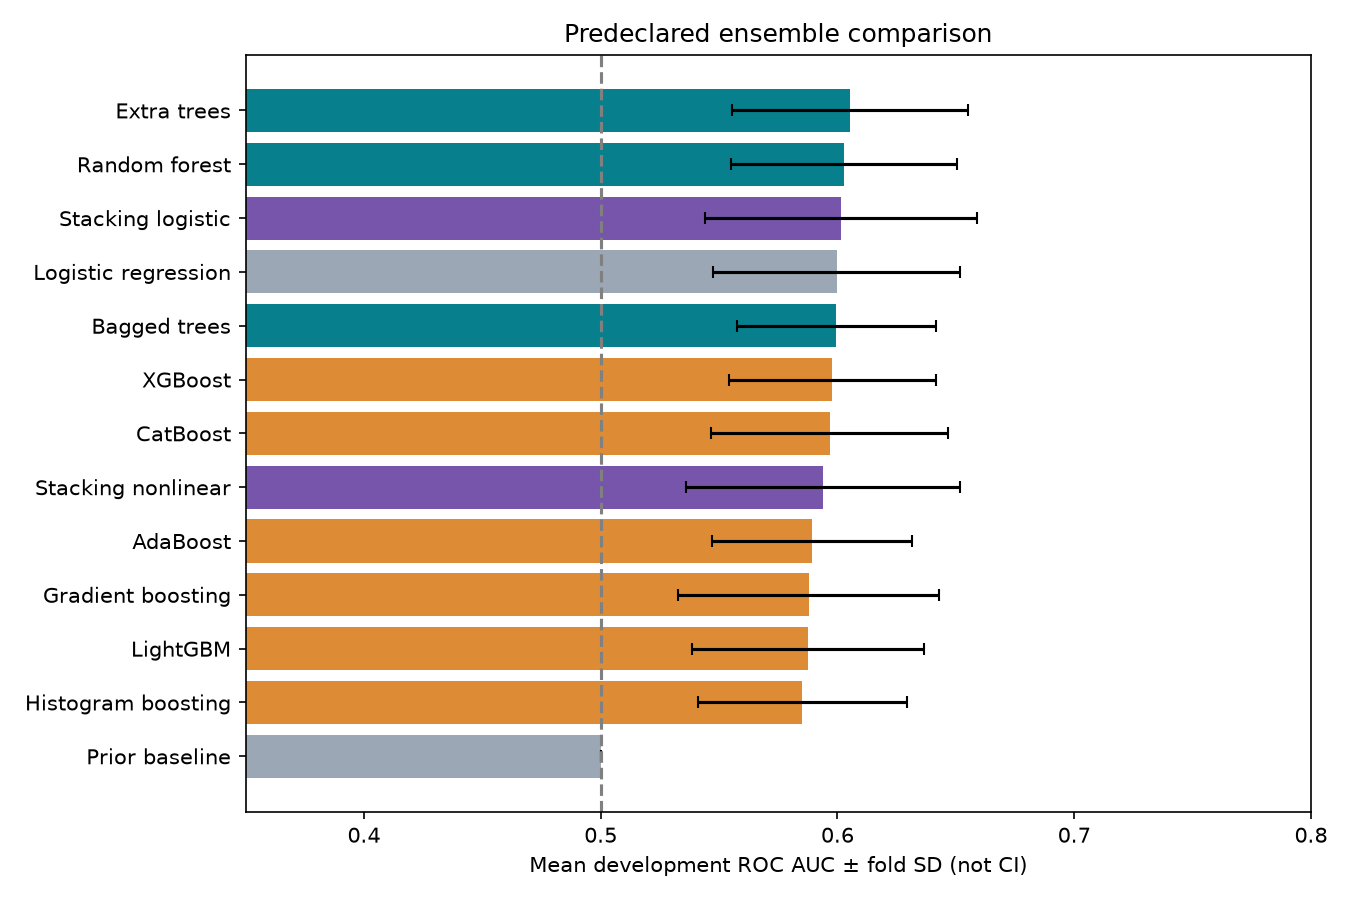

In [10]:
from train import ranked
ranked_cv = ranked(cv)
display(ranked_cv[['model','family','feature_set','candidate','mean_roc_auc','std_roc_auc','mean_average_precision']])
display(selection)
assert int(ranked_cv.iloc[0].spec_id) == selection['spec_id']
assert selection['test_used_for_selection'] is False
print('Chosen:', selection['selected_model'], '/', selection['feature_set'])
display(Image(filename=str(REPORTS / 'comparison.png')))

### Selection conclusion
Extra Trees with base features has development mean ROC AUC 0.6054, compared with 0.6000 for engineered Extra Trees. The deployed model therefore keeps the base representation. The winning mean is modest and scores are close; this is the best observed recipe under the declared criterion, not a claim of universal superiority.

## 8. Evaluate the frozen winner
Only the selected model and prior baseline are evaluated in the new holdout report. All precision/recall/F1 values use source Final code 1 as positive and threshold 0.50. Bootstrap intervals describe the fixed fitted model; they exclude full-search/selection and prevalence uncertainty. The historical holdout is internal research evidence.

1000 fixed-model class-stratified bootstrap samples; does not cover model selection or prevalence uncertainty


,metric,selected_model,prior_baseline,lower_95_percent,upper_95_percent
0,roc_auc,0.661228,0.500000,0.590221,0.731325
1,average_precision,0.533530,0.388430,0.460753,0.620867
2,accuracy,0.632231,0.611570,0.590909,0.673554
3,balanced_accuracy,0.553767,0.500000,0.509776,0.599208
4,precision,0.575758,0.000000,0.424213,0.724138
5,recall,0.202128,0.000000,0.127660,0.287234
6,f1,0.299213,0.000000,0.198473,0.400000
7,brier,0.221185,0.237552,0.208359,0.233710
8,log_loss,0.634214,0.668041,0.604958,0.664716


,Predicted code 2,Predicted code 1
Actual code 2,134,14
Actual code 1,75,19


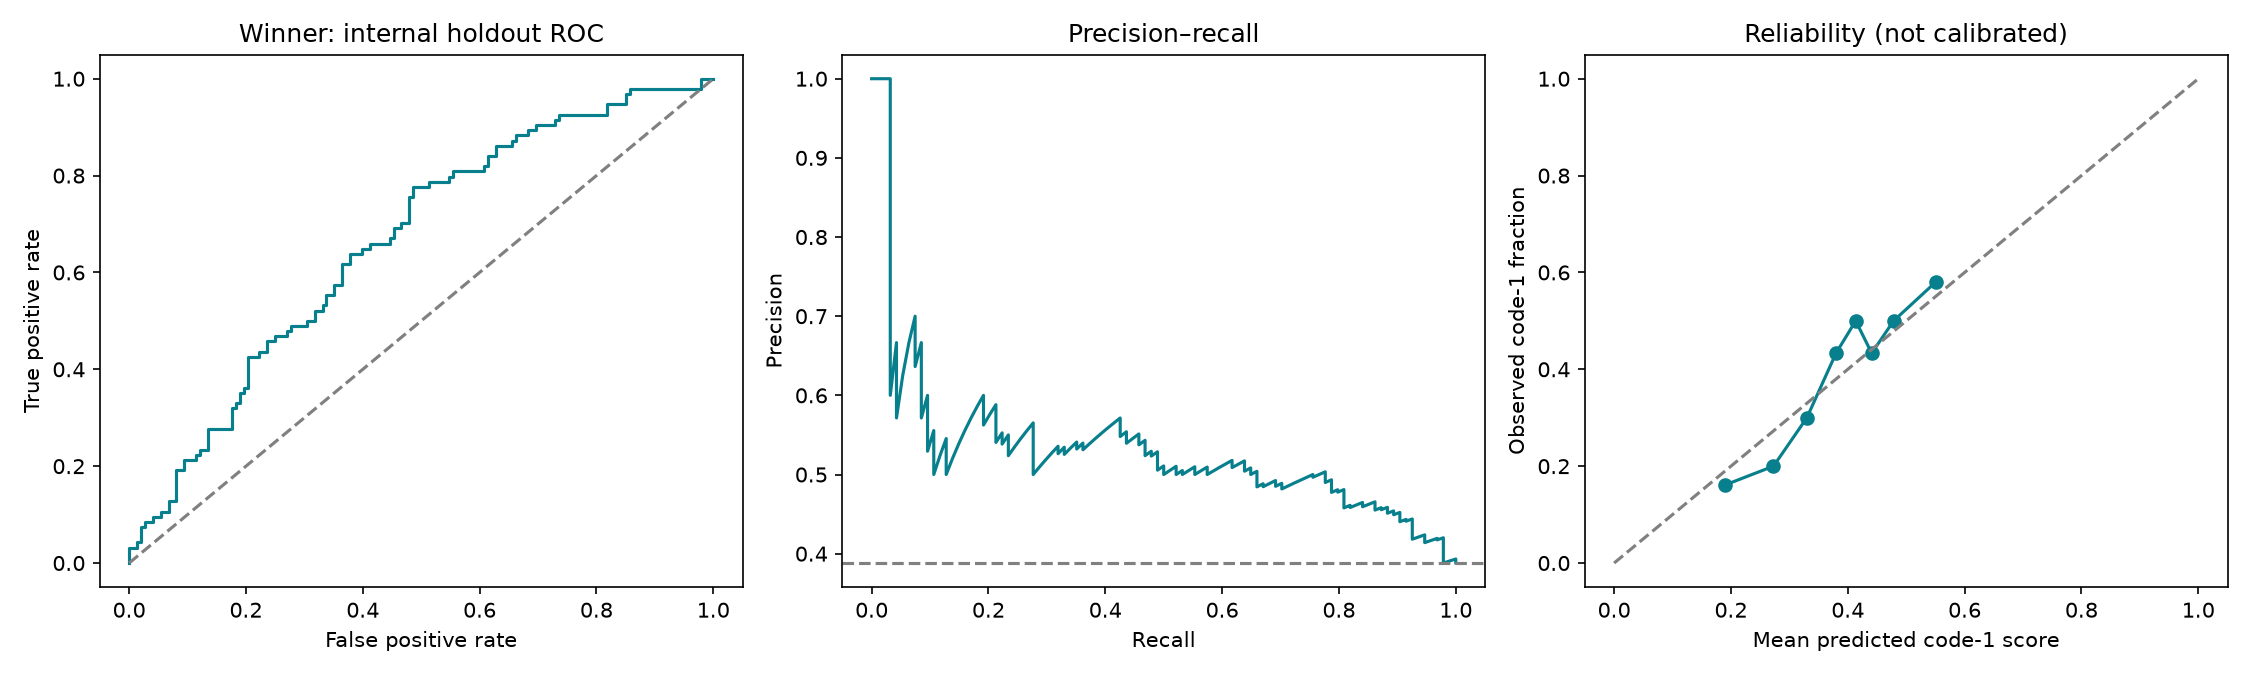

In [11]:
display(pd.DataFrame([{'metric':k, 'selected_model':v, 'prior_baseline':test['baseline_metrics'][k],
    'lower_95_percent':test['confidence_intervals'][k][0], 'upper_95_percent':test['confidence_intervals'][k][1]} for k,v in test['metrics'].items()]))
display(pd.DataFrame(test['confusion_matrix'], index=['Actual code 2','Actual code 1'], columns=['Predicted code 2','Predicted code 1']))
display(Image(filename=str(REPORTS / 'evaluation.png')))
print(test['confidence_interval_method'])

### Interpretation
ROC AUC is 0.6612 and average precision 0.5335 against code-1 prevalence 0.3884. At threshold 0.50 the model misses 75 of 94 code-1 records; recall is only 0.2021 and balanced accuracy 0.5538. Above-chance ranking does not make it useful as a diagnostic tool. The reliability plot is descriptive; probabilities are uncalibrated. A future operating threshold must be justified by verified outcome meaning and an explicit cost/benefit objective using development-only data, followed by independent evaluation.

## 9. Explain the chosen model after selection
### Global: original-feature permutation importance
Shuffle each original input on the internal holdout and measure the decrease in ROC AUC, repeating ten times. The full pipeline is rerun, preserving dependencies with any derived fields. Importance follows selection and does not drive post-test feature removal. Error bars show shuffle SD, not causal uncertainty. Correlated inputs can share/mask importance and negative values can occur.

,feature,mean_auc_drop,shuffle_std
0,Neckstiffnessad,0.073871,0.021822
1,Cnsuffusionad,0.011149,0.004271
2,Headachead,0.009567,0.003825
3,DBPadd,0.008654,0.008213
4,Stagnantwaterexposure,0.005470,0.002172
5,Chillsad,0.005104,0.003040
6,Sex,0.004967,0.005959
7,Otheragriexposure,0.004025,0.003799
8,SBPadd,0.003623,0.006953
9,Paddyfieldexposure,0.003457,0.003488


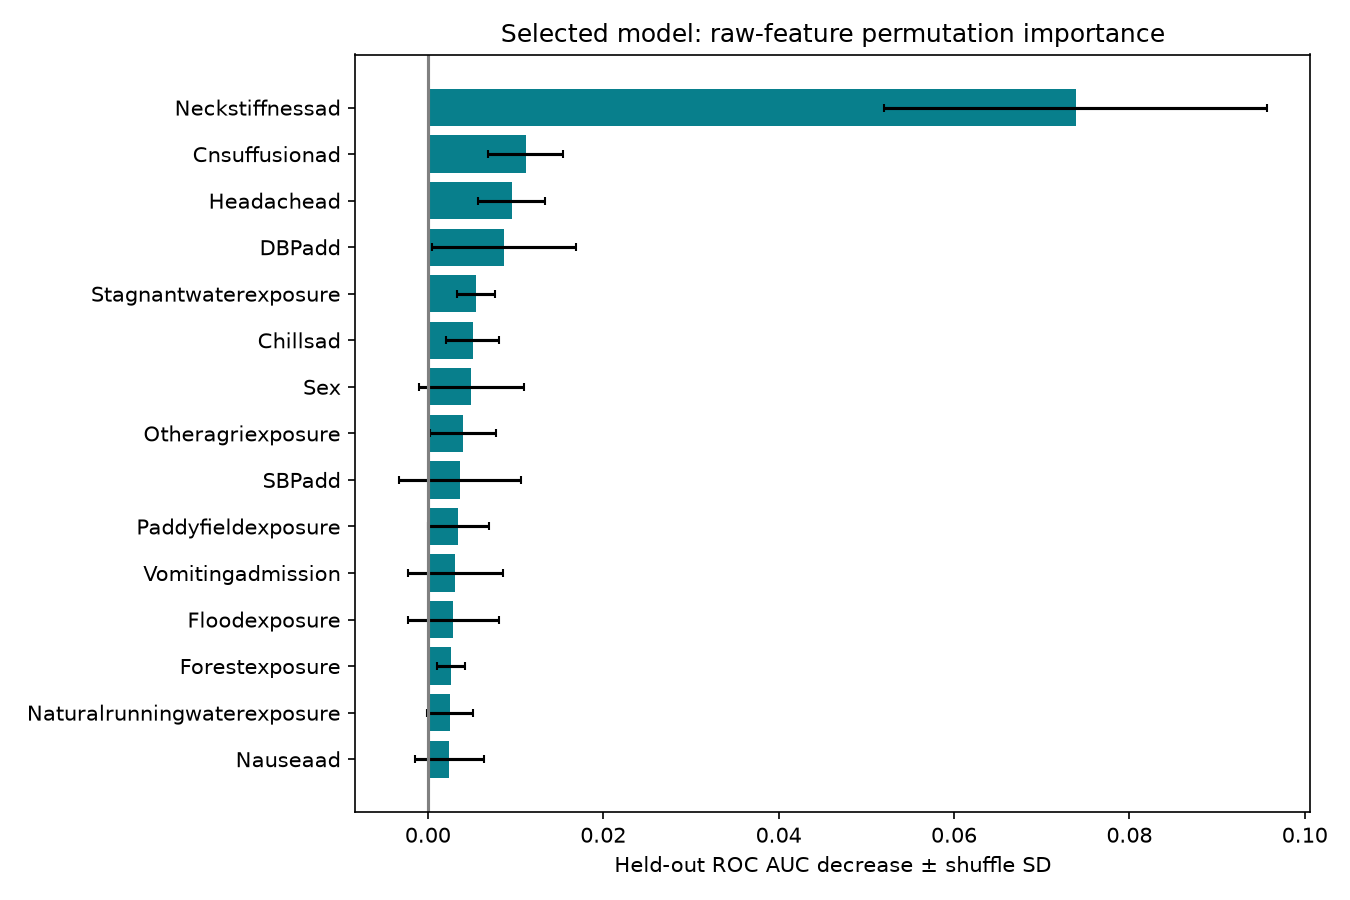

In [12]:
display(pd.read_csv(REPORTS / 'permutation_importance.csv'))
display(Image(filename=str(REPORTS / 'importance.png')))

### Local: reference-based Monte Carlo Shapley explanation
Use 24 random feature orders against one synthetic reference: development numeric medians and all source categories missing. Each order replaces reference values with example values and records marginal changes in code-1 probability. The average is a finite-permutation approximation; contributions telescope so baseline plus their sum reconstructs the prediction. This is a baseline-substitution game, not conditional population SHAP. Contributions depend on the reference, substitutions can be uncommon, and no causal or clinical interpretation follows.

Baseline 0.207422 + sum -0.130199 = prediction 0.077223


,feature,contribution,order_sampling_std
3,DBPadd,-0.057749,0.000562
1,PRad,-0.049762,0.003033
2,SBPadd,-0.030261,0.000562
5,Feverad,0.008456,0.003006
0,Age,-0.000882,0.000922
4,Sex,0.000000,0.000000
6,Headachead,0.000000,0.000000
7,Chillsad,0.000000,0.000000
8,Rigorsad,0.000000,0.000000
9,Musclepainad,0.000000,0.000000


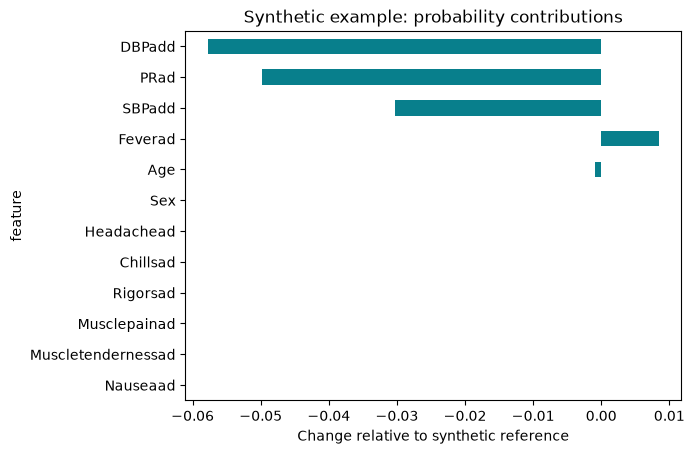

In [13]:
from src.explain import local_shapley
example = validate_record({'Age':35, 'Feverad':1})
base, predicted, local = local_shapley(model, example, reference)
print(f'Baseline {base:.6f} + sum {local.contribution.sum():+.6f} = prediction {predicted:.6f}')
assert np.isclose(base + local.contribution.sum(), model.predict_proba(example)[0,1])
display(local)
ax = local.head(12).iloc[::-1].plot.barh(x='feature', y='contribution', color='#087f8c', legend=False, title='Synthetic example: probability contributions')
ax.set_xlabel('Change relative to synthetic reference')
import matplotlib.pyplot as plt
plt.show()

### Synthetic one-feature response
The curve varies age with Feverad=1, other source categories missing and other numerics at development medians. This one fixed synthetic context is not a population effect and exposes no actual patient row.

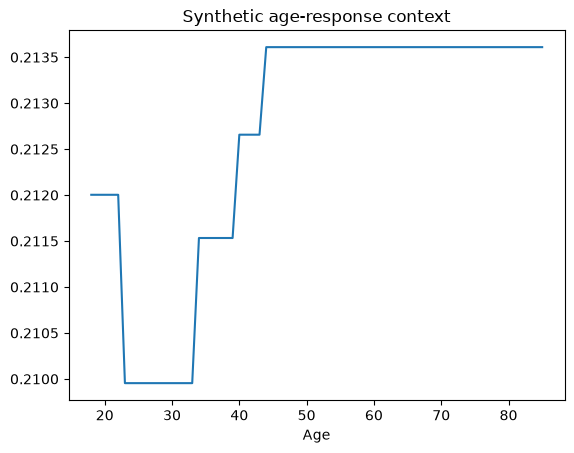

In [14]:
response = pd.read_csv(REPORTS / 'synthetic_age_response.csv')
response.plot(x='Age', y='code1_probability', title='Synthetic age-response context', legend=False)
plt.show()

## 10. Interactive serving and MLOps
Launch `python -m streamlit run app.py` from the repository root (or `../run_dashboard.ps1` from this folder). The UI serves the exact evaluated model, validates source-code inputs, displays immediate scores and explanations, and separates illustrative example thresholds from the published 0.50 metrics. Application code does not persist inputs.

The versioned artifact and reference contain no original patient tables; raw data and historical bundles stay local. Hash verification detects changed release bytes; only trusted project pickle artifacts should be loaded. The manifest records code/data/package/report provenance. Tests check the contract, leakage boundaries, selection, explanation reconstruction and interactive UI flow. GitHub Actions is configured; remote execution requires a push. Retraining and model promotion remain manual.

In [15]:
display({k:manifest[k] for k in ['model_version','model','feature_set','created_utc','python','source_data_sha256','packages']})
display(Markdown((ROOT / 'DEPLOYMENT.md').read_text(encoding='utf-8')))

{'model_version': '503bc9aeb6f8',
 'model': 'Extra trees',
 'feature_set': 'base',
 'created_utc': '2026-10-24T16:07:41.854944+00:00',
 'python': '3.12.14',
 'source_data_sha256': '8f15e42cf808f6c342b868995633eedac86a7648cc73f553c852191424e7e880',
 'packages': {'numpy': '2.5.3',
  'pandas': '3.0.6',
  'scikit-learn': '1.9.1',
  'scipy': '1.18.1',
  'joblib': '1.6.0',
  'xgboost': '3.4.1',
  'lightgbm': '4.7.0',
  'catboost': '1.2.10',
  'streamlit': '1.65.0'}}

# Free public hosting and basic MLOps

## Streamlit Community Cloud

Streamlit's [official documentation](https://docs.streamlit.io/deploy/streamlit-community-cloud) describes free hosting linked to GitHub. This app serves the saved Python model directly; GitHub Pages alone cannot execute its inference pipeline.

1. Push this folder to a public repository, suggested name `Pasansemage/sri-lanka-leptospirosis-ensemble-ml`.
2. Open [Streamlit Community Cloud](https://share.streamlit.io/) and sign in with the GitHub account that has admin access to the repository.
3. Choose **Create app**, repository `Pasansemage/sri-lanka-leptospirosis-ensemble-ml`, branch `main`, entrypoint **`app.py`** at the repository root.
4. In Advanced settings select **Python 3.12**. `requirements.txt` supplies the tested versions. No application secrets are required.
5. Optionally request an available subdomain such as `sri-lanka-leptospirosis-ml`, then Deploy. Availability is not guaranteed.
6. Confirm successful startup, compare the displayed model version with `artifacts/manifest.json`, and run the default hypothetical example followed by **Explain this prediction**.
7. Check the evidence and explanation tabs, then record the actual public URL in README. No public URL is provisioned by this local setup.

The source CSV is not needed for hosting. Keep it and historical patient-containing bundles out of the public repository.

Official references: [deployment](https://docs.streamlit.io/deploy/streamlit-community-cloud/deploy-your-app/deploy), [resources/app sleep](https://docs.streamlit.io/deploy/streamlit-community-cloud/manage-your-app), [limitations](https://docs.streamlit.io/deploy/streamlit-community-cloud/status). Checked 24 October 2026. Apps without traffic for 12 hours sleep and visitors can wake them; platform limits can change. This is a free academic demo with possible cold starts.

## Implemented MLOps

| Stage | Implementation |
|---|---|
| Reproducibility | Explicit source contract, seed 42, shared folds, declared compact grids |
| Selection | Mean development ROC AUC, exact ties by AP; choice persisted before test predictions |
| Evaluation | Winner and prior baseline, fixed threshold, fixed-model bootstrap intervals |
| Explainability | Raw-feature permutation importance and local Monte Carlo Shapley game |
| Versioning | Model-hash version, data/source/package/report hashes in manifest |
| Serving | Cached predictor, integrity/package checks, validated inputs, no startup training |
| Checks | Data contract, leakage boundaries, selection, explanations and interactive app tests |
| CI | GitHub Actions configuration for pushes and pull requests; execution requires publishing |
| History | Local append-only aggregate run history |

Retraining and promotion are manual. The app shows example inference latency; live drift/outcome monitoring and automatic retraining are not implemented.

## Release and rollback

1. Train locally with `python train.py` and inspect comparison, feature ablation, metrics and explanations. Keep the provisional codebook assumptions explicit.
2. Run `python -m unittest discover -s tests -v`. Confirm hypothetical inference and explanations work.
3. Commit code, requirements, artifacts, aggregate reports and documentation together. Inspect staged files for raw data or secrets.
4. Push and verify CI. Community Cloud follows the configured branch; it can redeploy before CI finishes, so this is **not a CI-gated promotion pipeline**. For a manual gate, deploy a dedicated release branch and update it only after checks pass on main.
5. Verify the public model version and example prediction after deployment.

Rollback by reverting the release commit (`git revert <commit>`) and pushing the revert, keeping code, requirements, reports and model in sync. Use Community Cloud logs for failures and its app controls for restarts. No application-level raw input logging is included. Future monitoring could track aggregate latency, errors and missingness shifts; meaningful model-performance monitoring requires independently obtained outcomes. Do not repeatedly tune against this historical holdout and call it independent validation.


## 11. Complete model card and presentation script
The model card records the outcome and limits. The spoken script follows this notebook and includes the measured model-selection, explainability and MLOps results.

In [16]:
display(Markdown((REPORTS / 'MODEL_CARD.md').read_text(encoding='utf-8')))
display(Markdown((ROOT / 'PRESENTATION_SCRIPT.md').read_text(encoding='utf-8')))

# Selected model: Extra trees

## Intended use and data contract

Academic comparison and hypothetical-record demonstration. Predict the numerical source label Final code 1 versus code 2 from admission-allowlisted inputs. Code meanings, numeric units and the 99 missing-value rule are not publisher-codebook verified. Do not interpret model output as a clinical diagnosis or calibrated risk.

The source contains 1734 rows and 806 columns. Eligibility requires Final in {1,2} and at least one recorded admission symptom, retaining 1206 records. Seed-42 stratification assigns 964 development and 242 holdout records. This reuses the earlier project's holdout; it is internal evaluation, not independent external validation.

## Selection evidence

36 declared combinations cover 13 methods, two feature representations and compact hyperparameter grids. Every candidate uses the same five development folds. Stacking has three inner folds with complete preprocessing pipelines. Equal class weights are used across the new benchmark. Highest mean validation ROC AUC selects the complete recipe; exact ties use validation average precision, then deterministic ordering.

Selected recipe: **Extra trees / base**, candidate 0, mean CV ROC AUC **0.6054**, fold SD **0.0500**, CV average precision **0.4920**. Fold SD is not a confidence interval or significance test. Extra Trees averages 150 randomized trees with min_samples_leaf=10, random_state=42 and bootstrap=False; it belongs in the randomized-averaging comparison but is not literal bootstrap bagging in this configuration.

Extra Trees with engineered features scores 0.6000 versus 0.6054 for base features (difference −0.0054). Therefore pulse pressure, approximate mean arterial pressure and documentation fractions are excluded from the deployed winner. Base preprocessing still includes numeric median imputation, missing indicators, scaling, categorical Missing values and one-hot encoding. The test does not choose model, features or threshold.

## Internal holdout metrics

| Metric | Selected model | Prior baseline |
|---|---:|---:|
| roc_auc | 0.6612 | 0.5000 |
| average_precision | 0.5335 | 0.3884 |
| accuracy | 0.6322 | 0.6116 |
| balanced_accuracy | 0.5538 | 0.5000 |
| precision | 0.5758 | 0.0000 |
| recall | 0.2021 | 0.0000 |
| f1 | 0.2992 | 0.0000 |
| brier | 0.2212 | 0.2376 |
| log_loss | 0.6342 | 0.6680 |

Threshold: 0.50. Confusion matrix: rows actual code 2/code 1, columns predicted code 2/code 1: **[[134,14],[75,19]]**. In particular, 75 of 94 code-1 records are missed at this threshold. ROC AUC 95% fixed-model stratified-bootstrap interval: **[0.5902, 0.7313]**. This excludes selection, prevalence and external-population uncertainty. Holdout code-1 prevalence is 0.3884; average precision should be compared with that prior baseline.

ROC AUC measures ranking; it does not establish high recall at threshold 0.50. The low code-1 recall (20.2%) materially limits usefulness. No threshold is optimized on the holdout. Probabilities are uncalibrated; Brier/log loss and a reliability plot are reported without claiming calibration.

## Explainability

Global: ten-repeat held-out permutation importance in the original input space, scored by ROC AUC drop. The full pipeline recomputes all descendant features for each shuffle. Highest measured mean drops: Neckstiffnessad, Cnsuffusionad, Headachead. Consult the shuffle SDs; correlated inputs can share or mask importance and negative importances can occur. This analysis follows selection and does not remove predictors.

Local: 24-permutation Monte Carlo Shapley values in probability units relative to one synthetic reference (development numeric medians, categorical inputs missing). Each path changes inputs from reference to example, and its marginal changes telescope exactly. Averaging approximates the order average; reference score plus summed contributions reconstructs the prediction. This is not population-conditional SHAP and baseline substitutions can be unrealistic. Neither method demonstrates causality.

The example is synthetic: Age=35, Feverad=1, everything else missing. Reference output **0.2074** plus summed contributions **-0.1302** equals example output **0.0772**. The synthetic age-response curve holds other inputs fixed; it is not a population effect.

## Serving and limitations

`artifacts/model.joblib` contains the fitted predictor, not the experiment bundles holding patient tables. The app needs no raw CSV. The manifest records data/code/package/report hashes and the model-hash version. Original data and historical patient-containing bundles stay local.

Important limits: provisional source semantics and sentinels, cohort selection, unverified timing/units, hospital/time shifts, missingness proxies, multiple-comparison optimism, correlated predictors, low recall, uncalibrated outputs, historical holdout reuse and lack of external validation. Verify the source codebook and obtain independent validation before stronger research claims. Hosted deployment, external monitoring and automatic model promotion are not completed by a local repository setup.


# Presentation script — Sri Lanka Leptospirosis ML

Suggested duration: 8–10 minutes. Bracketed cues describe what to show, not words to read aloud. Source labels remain neutral throughout. Values below come from the recorded run; regenerate this script if the model changes.

## 0:00–0:50 — Project purpose

[Open the modelling notebook introduction.]

This project compares ensemble classifiers using admission features from a Sri Lankan hospital-based febrile-patient study. My goal is to compare bagging, boosting and stacking fairly, choose a model using explicit evidence, explain what it learned, and serve it through an interactive application.

The source contains 1734 records and 806 columns. I use Final code 1 versus Final code 2 as numerical labels. Their clinical meanings and the missing-value convention still need verification against the publisher's CSV codebook. I therefore present this as an academic modelling demonstration, not a clinical diagnostic tool.

## 0:50–2:10 — Feature engineering and leakage

[Show the feature-engineering decision table and ablation results.]

I define the prediction point as admission. The allowlist retains 54 original inputs: age, pulse, two blood-pressure fields, sex codes, 29 symptom fields and 20 exposure-history fields. Identifiers, hospital and collection context, diagnostic tests, follow-up measurements, and uncertain-time laboratory values are excluded. This reduces direct outcome leakage and avoids memorizing patient identifiers or recruitment context.

I preserve the earlier cohort rule: a record needs a supported outcome code and at least one recorded admission symptom. That leaves 1206 records. This selects a subgroup, so it limits generalization.

Blank or invalid values and source 99 are provisionally treated as missing. This is an explicit assumption: a real measurement equal to 99 could be lost, which is why codebook verification matters. Broad fixed numeric bounds catch gross input errors. I use median imputation and missing indicators for numerics, plus a Missing category and one-hot encoding for categorical codes. I do not assume code 1 means presence. All learned preprocessing is fitted using the fitting fold only.

I also test four derived inputs: pulse pressure, approximate mean arterial pressure, and the fraction of symptom and exposure fields that were recorded. The first two expose combinations of numeric inputs; the fractions describe documentation completeness, not symptom burden. These features might help shallow models, but they are correlated and may capture hospital recording practices.

I test the base and engineered representations on identical development folds. For the winning Extra Trees model, engineering lowers mean AUC from 0.6054 to 0.6000. I therefore deploy the base representation. Feature engineering is evaluated rather than assumed beneficial.

## 2:10–3:40 — Bagging, boosting and stacking

[Show the three comparison sections and the combined chart.]

The comparison includes 13 methods and 36 complete recipes. I preserve a stratified 80/20 split with seed 42: 964 development records and 242 internal holdout records. The development set has five identical stratified folds for every candidate.

The bagging comparison includes bagged decision trees, random forest and Extra Trees. Bagged trees bootstrap training subsets and average predictions. Random forest also randomizes feature choices at splits. Extra Trees adds random split thresholds. Its configuration here uses the full fitting fold rather than bootstrap samples, so it is more precisely a randomized averaging ensemble grouped with the bagging comparison.

Boosting fits learners sequentially to improve an objective. I compare AdaBoost, gradient boosting, histogram gradient boosting, XGBoost, LightGBM and CatBoost. Their capacity and regularization settings are intentionally modest. CatBoost receives the shared one-hot representation here, so this is a controlled common-preprocessing comparison, not a demonstration of its native categorical mode.

Stacking learns a combiner from predictions of logistic regression, random forest and gradient boosting. I compare a regularized logistic combiner and a shallow nonlinear boosting combiner. Each uses three inner folds to generate out-of-fold predictions. Complete base pipelines, including imputers and encoders, are fitted inside those inner folds. Fitting preprocessing outside the stack would leak information into the meta-training procedure.

The prior classifier and logistic regression provide reference points. Every model uses equal class weights in this new comparison. These small grids do not establish a globally optimal architecture.

## 3:40–5:00 — Choosing the winner and interpreting metrics

[Show selection.json, the development leaderboard and held-out metrics.]

My primary selection metric is mean development ROC AUC. It evaluates how well code-1 records are ranked above code-2 records across thresholds. Exact AUC ties use development average precision, then a deterministic ordering. The winner is written to disk before held-out predictions are evaluated.

Extra trees with base features wins with mean development ROC AUC 0.6054. Its fold standard deviation is 0.0500. The scores are close, so I do not claim statistical superiority from the winning mean.

On the internal holdout, ROC AUC is 0.6612. Average precision is 0.5335, compared with code-1 prevalence 0.3884. Accuracy is 0.6322 versus 0.6116 for the prior baseline, so accuracy alone would exaggerate what the model achieves.

At the fixed 0.50 threshold, precision is 0.5758, recall is 0.2021, and F1 is 0.2992. The confusion matrix contains 134 correctly predicted code-2 records, 14 code-2 records predicted as code 1, 75 missed code-1 records, and 19 correctly predicted code-1 records. The recall limitation is substantial even though AUC is above chance.

Brier score is 0.2212 and log loss is 0.6342; lower is better. I show a reliability plot but do not call the probabilities calibrated. A fixed-model bootstrap AUC interval is approximately 0.5902 to 0.7313. It does not capture model-selection uncertainty.

This is the same historical holdout used earlier in the project, so it is internal evaluation. Independent temporal or external validation remains future work. I do not choose a new threshold by inspecting this holdout.

## 5:00–6:30 — Explain the chosen model

[Open the global importance chart, then run the synthetic example's local explanation.]

I explain the selected Extra Trees predictor after model selection. For global importance, I shuffle one original input at a time on the holdout and measure the ROC AUC decrease. Ten shuffles estimate sensitivity to the shuffle. Using the original columns makes the result easier to interpret and preserves the dependency between an original input and any derived descendants.

The top measured inputs by mean drop are Neckstiffnessad, Cnsuffusionad, Headachead. The error bars are shuffle standard deviations, not evidence of causal effects. Correlated inputs can mask each other, and unimportant-looking inputs for this model are not necessarily unimportant in the population.

For an individual prediction, I use a Monte Carlo Shapley substitution game. The reference is synthetic: development medians for numeric inputs and Missing for the categorical codes. Across 24 random feature orders, I replace reference inputs with the submitted values and average the marginal score changes.

Positive contributions move the model toward source code 1 relative to this reference. The reference score plus all contributions reconstructs the prediction. This is an approximate order average against one reference, not conditional population SHAP. It is reference-dependent, and some substitutions can be unrealistic. It explains how this fitted predictor behaves, not what causes an outcome.

The example uses age 35 and Feverad code 1, with other fields missing. It is a hypothetical record, not an exposed patient row. The separate age-response plot changes age in one fixed synthetic context and must not be interpreted as a population effect.

## 6:30–7:30 — Interactive application

[Open the app's Live prediction tab. Submit the default example; click Explain this prediction.]

The application loads the same saved fitted model that was evaluated. It checks the artifact and report hashes and the key package versions. The source CSV is not required for serving and the app does not retrain at startup.

I can enter hypothetical admission inputs and get an immediate code-1 score, predicted source code and inference latency. Missing inputs use the same contract as training. The example requires at least one recorded symptom code and rejects invalid codes or inconsistent supplied blood pressures.

The threshold slider changes the displayed label for this example only. Published benchmark metrics remain at 0.50. The app also shows the development comparisons, holdout evidence, engineering ablation, global explanations and release provenance. The application does not persist submitted inputs.

## 7:30–9:00 — MLOps and free public hosting

[Show the repository, workflow file, manifest and DEPLOYMENT.md.]

The MLOps work makes this experiment reproducible and deployable. Source code and documentation live in Git. Training records the dataset hash, source hashes, package versions, seed, selected recipe and aggregate results. A SHA-256 prefix identifies the fitted model version.

Tests verify the data contract, fold-local preprocessing, stacking boundaries, development-only selection, finite predictions, explanation reconstruction and the interactive inference flow. GitHub Actions is configured to run these checks after the repository is pushed. Local configuration is not proof that remote CI has passed.

For free hosting, I will use Streamlit Community Cloud with the public GitHub repository. The deployment settings are branch main, entrypoint app.py and Python 3.12. The host installs the pinned requirements and serves the committed artifact. The raw CSV and patient-containing historical experiment bundles remain local.

Once deployed, I will confirm the public app's displayed model hash and run the hypothetical example. Community Cloud follows the configured GitHub branch; it can redeploy before CI finishes. A dedicated release branch updated after tests pass would provide a stronger manual promotion gate. A rollback must restore matching code, requirements, model and reports together.

Free hosting can sleep when idle, so cold starts are expected. Runtime logs help diagnose errors, while actual population drift and outcome monitoring are future work. No automatic retraining or performance monitoring is claimed.

The main findings are that a simple randomized ensemble wins this declared comparison, plausible engineered inputs do not automatically help, and above-chance ranking does not remove the low-recall limitation. The result is a transparent academic demo with reproducible evidence and a concrete public deployment path.


## Sources
- Dataset: Suneth Agampodi, [Mendeley Data v4](https://data.mendeley.com/datasets/zmxmp42g9p/4), CC BY 4.0.
- [scikit-learn StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html): internal out-of-fold meta-training.
- [scikit-learn permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html): score-based model inspection and limitations.
- [Streamlit Community Cloud](https://docs.streamlit.io/deploy/streamlit-community-cloud): hosting path, detailed in DEPLOYMENT.md.